In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/bank-additional-full.csv", sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:

# Basic information about our dataset

print("DATASET INFORMATION")
df.info()

print("\nNUMERICAL VARIABLES")
print(df.select_dtypes(include=["number"]).columns.tolist())

print("\nCATEGORICAL VARIABLES")
print(df.select_dtypes(include=["object"]).columns.tolist())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nUNKNOWN VALUES")
print((df == "unknown").sum())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.i

### Initial Data Exploration

The Bank Marketing dataset contains 41,188 observations and 21 columns, including 20 input features and one target variable. Among the input features, 10 are numerical and 10 are categorical.

The initial inspection showed no standard missing values. However, several categorical variables contain `unknown` values, especially `default` (8,597 cases) and `education` (1,731 cases). We will investigate these values during preprocessing rather than removing them immediately, since deleting a large number of observations could affect the dataset and our results.

Number of customers:
y
no     36548
yes     4640
Name: count, dtype: int64

Percentage of customers:
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


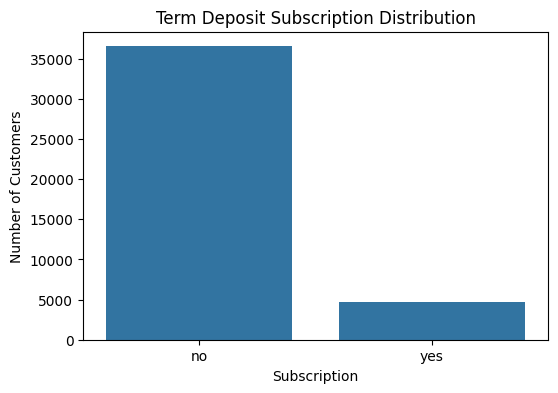

In [ ]:

# Target variable distribution

print("Number of customers:")
print(df["y"].value_counts())

print("\nPercentage of customers:")
print(df["y"].value_counts(normalize=True) * 100)

# Visualization
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="y")

plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()


### Target Variable Analysis

The target variable `y` shows that most customers did not subscribe to a term deposit. Out of 41,188 observations, 36,548 (88.73%) belong to the `no` class, while only 4,640 (11.27%) belong to the `yes` class.

This shows that our dataset is imbalanced. A model that always predicts `no` could achieve high accuracy without correctly identifying any subscribers.

Because of this, we will focus on metrics such as precision, recall, F1-score and Average Precision when evaluating our models, rather than relying only on accuracy.

Minimum age: 17
Maximum age: 98
Average age: 40.02
Median age: 38.0


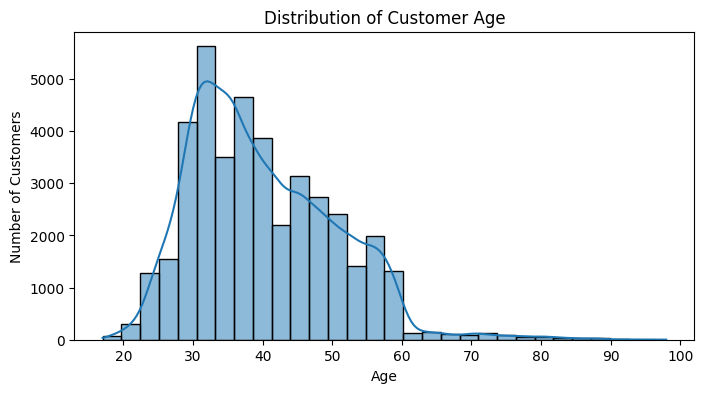

In [ ]:

# Descriptive statistics for customer age

print("Minimum age:", df["age"].min())
print("Maximum age:", df["age"].max())
print("Average age:", round(df["age"].mean(), 2))
print("Median age:", df["age"].median())

# Age distribution
plt.figure(figsize=(8, 4))

sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()


### Age Distribution Analysis

Customer ages range from 17 to 98 years, with an average age of 40.02 and a median of 38.

Most customers are between approximately 25 and 60 years old, especially around their 30s. The distribution is slightly right-skewed, with relatively few customers above 60.

This suggests that the dataset mainly represents middle-aged customers. However, we still need to investigate whether age is associated with term deposit subscriptions.

3. EDA Step 5 — Does age influence subscription?
Now we're going to do something more interesting.

Instead of just looking at age, we'll compare age with our target variable y.

We want to answer:

Do customers in certain age groups subscribe more often than others?

We'll create age groups and calculate the subscription rate for each group.

,age_group,subscription_rate
0,<25,23.970037
1,25-34,12.173024
2,35-44,8.651852
3,45-54,8.651195
4,55-64,13.568825
5,65+,47.209653


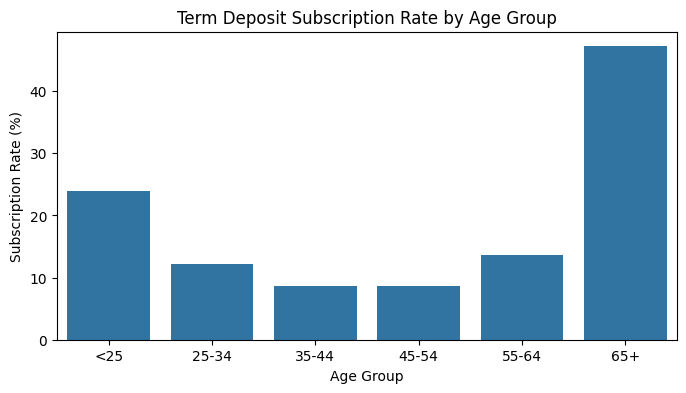

In [ ]:

# Create age groups for EDA
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["<25", "25-34", "35-44",
            "45-54", "55-64", "65+"],
    right=False
)

# Calculate subscription rate for each age group
age_subscription = (
    df.groupby("age_group", observed=True)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="subscription_rate")
)

display(age_subscription)

# Plot the subscription rate
plt.figure(figsize=(8, 4))

sns.barplot(
    data=age_subscription,
    x="age_group",
    y="subscription_rate"
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

plt.show()


### Subscription Rate by Age Group

The subscription rate varies quite a lot across age groups. Customers aged 65 and above have the highest rate, at approximately 47.2%, while customers under 25 also show a relatively high rate of around 24%.

In comparison, customers aged between 35 and 54 have much lower subscription rates, around 9%.

This suggests that age may be related to term deposit subscription. However, we still need to check the number of customers in each group, especially among older customers, before drawing stronger conclusions.

In [ ]:

# Number of customers and subscribers by age group

age_summary = df.groupby(
    "age_group",
    observed=True
).agg(
    total_customers=("y", "size"),
    subscribers=("y", lambda x: (x == "yes").sum())
)

age_summary["subscription_rate"] = (
    age_summary["subscribers"]
    / age_summary["total_customers"] * 100
).round(2)

display(age_summary)


,total_customers,subscribers,subscription_rate
age_group,,,
<25,1068,256,23.97
25-34,13686,1666,12.17
35-44,13500,1168,8.65
45-54,8704,753,8.65
55-64,3567,484,13.57
65+,663,313,47.21


### Age and Subscription Analysis

The results show that subscription rates vary across age groups. Customers aged 65 and above have the highest subscription rate (47.21%), followed by customers under 25 (23.97%). In comparison, customers between 35 and 54 have the lowest rate, at 8.65%.

However, the 65+ group contains only 663 customers, compared with more than 13,000 in each of the 25–34 and 35–44 groups. This means we should be careful when interpreting the higher subscription rate among older customers.

Overall, age appears to be associated with term deposit subscription, although other customer characteristics may also influence these differences.


3. EDA Step 6 — Analyze categorical variables
Now let's look at job.

We want to find out whether customers with different occupations have different subscription rates.

For example, do retired customers subscribe more often than technicians or people working in administration?

,total_customers,subscribers,subscription_rate
job,,,
student,875,275,31.43
retired,1720,434,25.23
unemployed,1014,144,14.20
admin.,10422,1352,12.97
management,2924,328,11.22
unknown,330,37,11.21
technician,6743,730,10.83
self-employed,1421,149,10.49
housemaid,1060,106,10.00


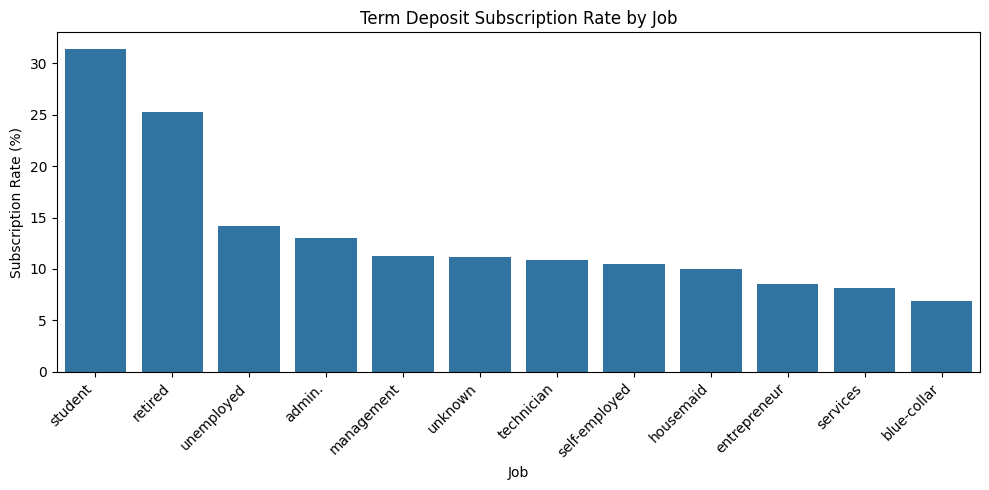

In [ ]:

# Subscription rate by job

job_summary = df.groupby("job").agg(
    total_customers=("y", "size"),
    subscribers=("y", lambda x: (x == "yes").sum())
)

job_summary["subscription_rate"] = (
    job_summary["subscribers"]
    / job_summary["total_customers"] * 100
).round(2)

job_summary = job_summary.sort_values(
    "subscription_rate",
    ascending=False
)

display(job_summary)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=job_summary.reset_index(),
    x="job",
    y="subscription_rate"
)

plt.xticks(rotation=45, ha="right")
plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()


### Subscription Rate by Occupation

Subscription rates differ across occupational groups. Students have the highest rate, at approximately 31%, followed by retired customers at around 25%. In contrast, blue-collar workers have the lowest subscription rate, at approximately 6.9%.

These differences suggest that occupation may be associated with subscription behavior. However, age could also play a role, since students and retired customers generally belong to different age groups.

We will need to consider the number of customers in each category and examine whether these relationships remain useful when building our Machine Learning models.

3. EDA Step 7 — Education level and subscription

,total_customers,subscribers,subscription_rate
education,,,
illiterate,18,4,22.22
unknown,1731,251,14.50
university.degree,12168,1670,13.72
professional.course,5243,595,11.35
high.school,9515,1031,10.84
basic.4y,4176,428,10.25
basic.6y,2292,188,8.20
basic.9y,6045,473,7.82


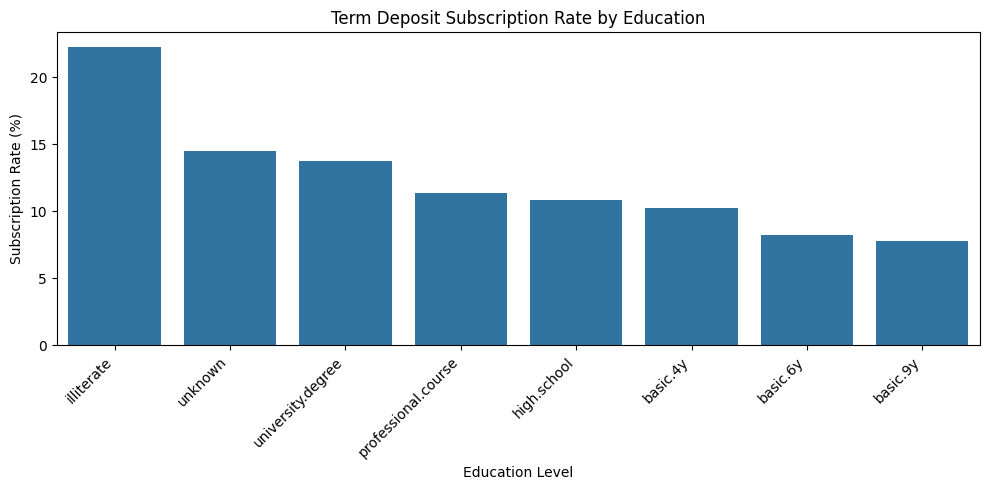

In [ ]:

# Subscription rate by education level

education_summary = df.groupby("education").agg(
    total_customers=("y", "size"),
    subscribers=("y", lambda x: (x == "yes").sum())
)

education_summary["subscription_rate"] = (
    education_summary["subscribers"]
    / education_summary["total_customers"] * 100
).round(2)

education_summary = education_summary.sort_values(
    "subscription_rate",
    ascending=False
)

display(education_summary)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=education_summary.reset_index(),
    x="education",
    y="subscription_rate"
)

plt.xticks(rotation=45, ha="right")
plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()


### Education Level and Subscription Analysis

Subscription rates vary across education levels. The highest rate is observed among customers classified as illiterate, at approximately 22%, followed by customers with unknown education levels and university degrees.

However, the illiterate category contains very few observations, so its high subscription rate should be interpreted carefully.

Customers with basic education, particularly those in the `basic.6y` and `basic.9y` categories, generally have lower subscription rates.

These results suggest that education may be associated with term deposit subscription, although the differences could also be related to other customer characteristics.

In [ ]:

# Number of customers and subscribers by education

education_counts = df.groupby("education").agg(
    total_customers=("y", "size"),
    subscribers=("y", lambda x: (x == "yes").sum())
)

education_counts["subscription_rate"] = (
    education_counts["subscribers"]
    / education_counts["total_customers"] * 100
).round(2)

education_counts = education_counts.sort_values(
    "subscription_rate",
    ascending=False
)

display(education_counts)


,total_customers,subscribers,subscription_rate
education,,,
illiterate,18,4,22.22
unknown,1731,251,14.50
university.degree,12168,1670,13.72
professional.course,5243,595,11.35
high.school,9515,1031,10.84
basic.4y,4176,428,10.25
basic.6y,2292,188,8.20
basic.9y,6045,473,7.82


### Education Level Analysis — Interpretation

The results show some differences in subscription rates across education levels. The highest rate appears in the illiterate category (22.22%), but this group contains only 18 customers, of whom four subscribed. Because the sample is so small, this result should be interpreted carefully.

University graduates have a subscription rate of 13.72%, based on a much larger group of 12,168 customers. Customers with basic nine-year education have the lowest rate, at 7.82%.

Overall, education seems to be associated with subscription behavior, but the differences do not follow a simple pattern. Other factors, such as age or previous marketing history, may also be involved.

Analyze the remaining numerical variables

,count,mean,std,min,25%,50%,75%,max
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


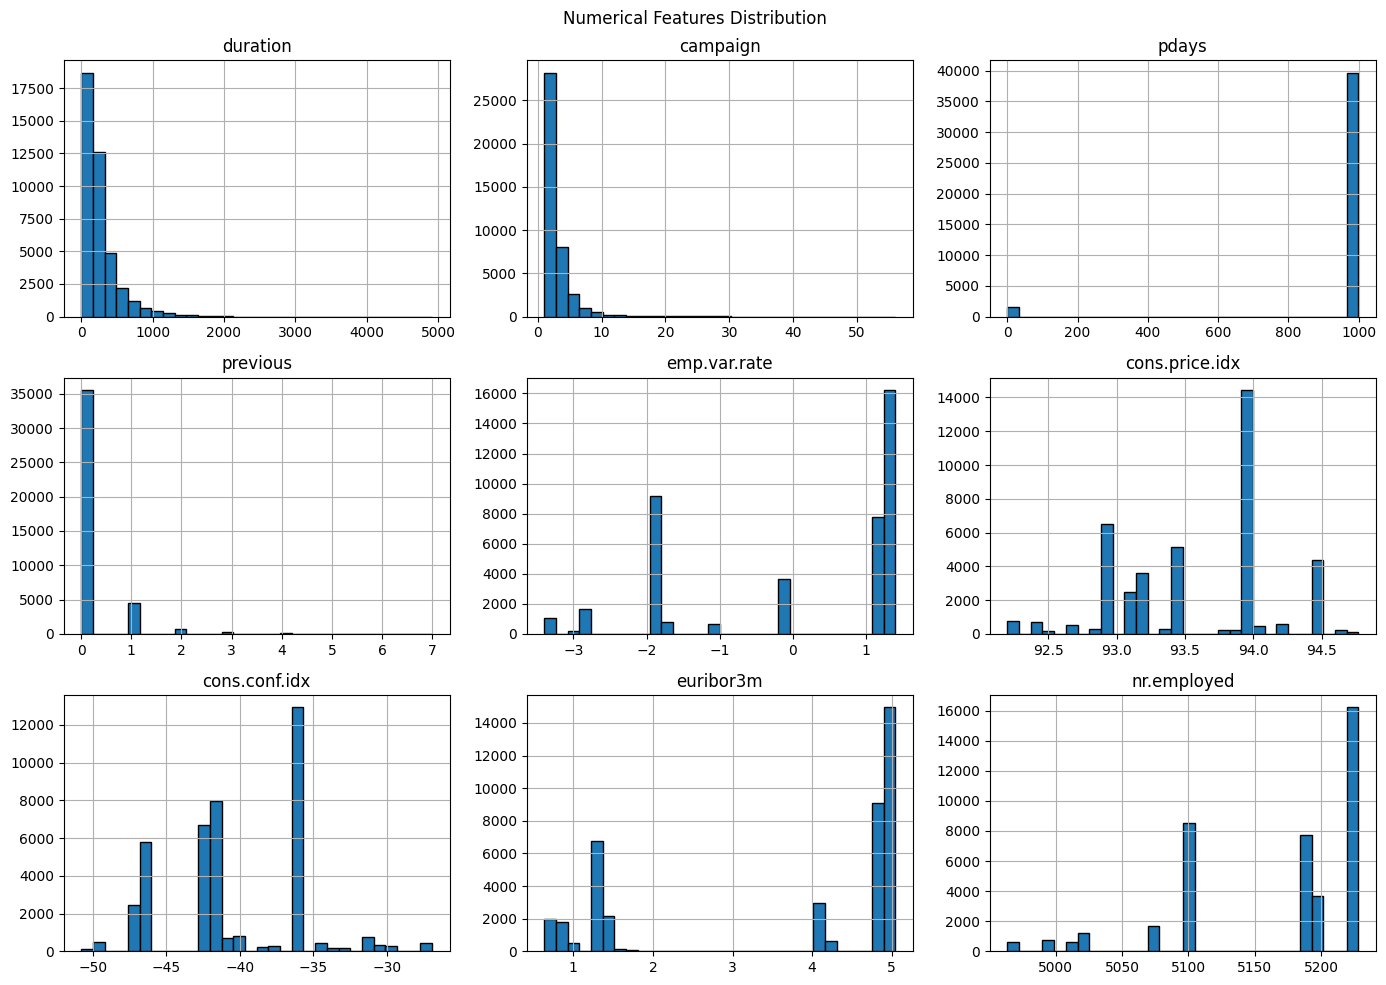

In [ ]:

# Numerical features (excluding age)

numerical_features = [
    "duration", "campaign", "pdays",
    "previous", "emp.var.rate",
    "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed"
]

# Descriptive statistics
display(df[numerical_features].describe().T.round(2))

# Histograms
df[numerical_features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Numerical Features Distribution")
plt.tight_layout()
plt.show()


### Numerical Features Analysis

The numerical features show different distribution patterns. Call duration is strongly right-skewed, with an average of 258.29 seconds and a maximum of 4,918 seconds. The number of campaign contacts is also right-skewed, with most customers contacted only a few times.

The `pdays` variable contains many values equal to 999, which indicates that the customer was not previously contacted. This value will require special treatment during preprocessing.

The `previous` variable is mostly concentrated at zero, suggesting that many customers have no recorded previous campaign contacts.

Economic indicators such as `euribor3m`, `emp.var.rate` and `nr.employed` show distinct clusters of values, which may reflect different economic periods.

Since our objective is to predict subscription before a marketing call, we will exclude `duration` from model training to avoid data leakage.

Check duplicate rows

In [ ]:

# Check duplicate observations

print("Total observations:", len(df))

print("Number of duplicate rows:",
      df.duplicated().sum())

print("Percentage of duplicates:",
      round(df.duplicated().mean() * 100, 2), "%")


Total observations: 41188
Number of duplicate rows: 12
Percentage of duplicates: 0.03 %


### Duplicate Observations Analysis

The dataset contains 41,188 observations, including 12 duplicate rows (approximately 0.03%). This represents a very small proportion of the dataset.

Since there is no unique customer identifier, identical rows do not necessarily correspond to duplicate customer records. We will review these observations during preprocessing before deciding whether to remove them.

# Week 2 – Data Preparation and Baseline

## 1. Dataset Cleaning